# Edge-Preserving CT Denoising: from first principles
**One question:** when you remove noise from a CT image, how far does the edge between two materials move, and does the usual quality score (PSNR) tell you?

Each chapter: **what -> why -> tiny demo -> test**. Run top to bottom. Every code cell starts with a `# [tag] ...` line: what it is for, and where to run it.

### How to use this notebook
| Tag | Meaning |
|---|---|
| `[RUN NOW]` | quick, laptop, seconds |
| `[RUN ONCE]` | slow but cached on disk, so a second run is instant |
| `[KAGGLE]` | needs the GPU (hours on the laptop's 4 GB card) |
| `[AFTER TRAINING]` | only works once the networks are trained |

**Files that must sit next to this notebook:** `phantom.py scanner.py metrics.py baselines.py models.py losses.py data.py train.py experiments.py loader.py test_phantom.py`

| Chapters | What happens | Where | Time |
|---|---|---|---|
| 2 - 7 | build each piece and run its tests | laptop | seconds each |
| 8 | make the noisy phantom datasets | laptop or Kaggle | 5-12 min, once |
| 9 | tune filters, train 13 networks, score everything | tune: laptop, train: **Kaggle** | see timing cell |
| 10 | the three new findings | either | minutes |
| 11 | real CT check | laptop | minutes |

In [39]:
# [RUN THIS AT THE START] 
import glob, shutil, sys, os, subprocess, torch
for f in glob.glob("/kaggle/input/**/*.py", recursive=True): shutil.copy(f, "/kaggle/working/")
sys.path.insert(0, "/kaggle/working"); os.chdir("/kaggle/working")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydicom"])
print(len(glob.glob("*.py")), "py files | GPU:", torch.cuda.is_available())

9 py files | GPU: True


In [6]:
# [RUN NOW] confirm the notebook runs inside the LML environment (path must contain envs\LML)
import sys; print(sys.executable)

/usr/bin/python3


## 0. How this differs from a typical project
| Typical | Here |
|---|---|
| Add random noise to the image | Simulate the scanner: sinogram -> photon (Poisson) noise -> FBP reconstruction |
| Edges found with Canny (threshold-dependent) | Exact analytic boundary of every shape; sub-pixel, no thresholds |
| Judge by PSNR/SSIM | Judge by edge error, worst-case (Hausdorff), 10-90% edge width, measured feature size |
| Report one run | 3 seeds, error bars, unseen noise levels |
| Show the model wins | Test **why** edges blur (theory) and **where PSNR picks the wrong model** |

## 1. The physics in five lines
X-rays attenuate: I = N0 * exp(-integral of mu). A detector counts photons (Poisson). CT reconstructs mu from many angles. Hounsfield units: HU = 1000*(mu - mu_water)/mu_water. Noise is NOT white in the final image: the ramp filter in FBP amplifies high frequencies, so noise is correlated between neighbouring pixels.

**Check yourself:** why does halving the photon count N0 not halve the noise?

## 2. Phantoms with exact edges  (`phantom.py`)
We draw the shapes, so we know the true boundary to sub-pixel accuracy. Truth = dense points along every shape boundary, kept only where the material really changes. Distance to truth = one KD-tree query. No Canny, no threshold.

In [7]:
# [RUN NOW] run the phantom tests: shapes, exact circle area, exact edge position (6 'ok' lines expected)
!{sys.executable} test_phantom.py

/usr/bin/python3: can't open file '/kaggle/working/test_phantom.py': [Errno 2] No such file or directory


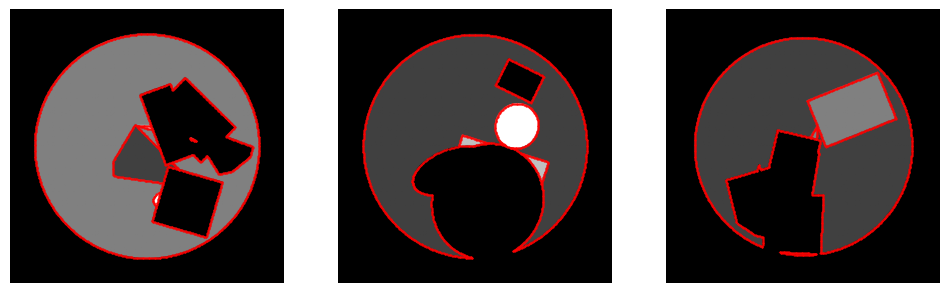

In [8]:
# [RUN NOW] look at 3 random phantoms; red dots = the exact true edges
import numpy as np, matplotlib.pyplot as plt
from phantom import make_phantom, dist_to_edges
rng = np.random.default_rng(7)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a in ax:
    img, e, _ = make_phantom(rng)
    a.imshow(img, cmap='gray', vmin=0, vmax=1); a.plot(e[::8,0], e[::8,1], 'r.', ms=1); a.axis('off')
plt.show()

## 3. Scanner noise  (`scanner.py`)
Radon transform -> Beer-Lambert -> Poisson photon counts -> Gaussian electronic noise -> -log -> filtered back-projection. Tests: the round trip recovers the image without shifting it; photon counts match N0*exp(-p); the noise is correlated, not white. **N0 = photons per ray: smaller N0 = noisier.**

In [9]:
# [RUN NOW] run the scanner tests (5 'ok' lines expected)
%run scanner.py

ok test_noise_free_roundtrip_and_no_shift
ok test_poisson_stats_and_beer_lambert
ok test_more_photons_less_noise
ok test_noise_is_correlated_not_white
ok test_shape_dtype_finite_seeded_starvation
All scanner tests passed. 6.8 s


<Figure size 640x480 with 0 Axes>

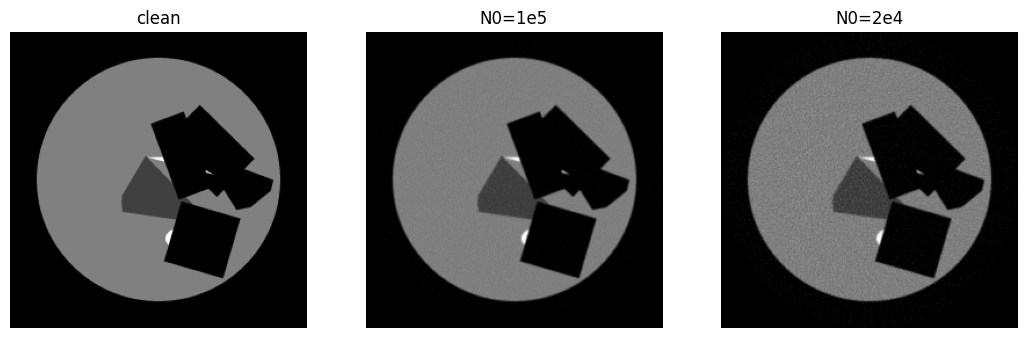

In [10]:
# [RUN NOW] see the same phantom at two noise levels; edges stay in place, grain grows as N0 drops
import numpy as np, matplotlib.pyplot as plt
from phantom import make_phantom
from scanner import scan
img, e, _ = make_phantom(np.random.default_rng(7))
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (t, x) in zip(ax, [("clean", img), ("N0=1e5", scan(img, 1e5)), ("N0=2e4", scan(img, 2e4))]):
    a.imshow(x, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.show()

## 4. How we judge success  (`metrics.py`)
Defined before any network exists, so nobody can bend the yardstick afterwards.
- **Edge error (px):** from the true edge, walk along the true normal to where the image crosses the half-way value between the two materials.
- **Edge width (px):** 10-90% rise distance across the edge. Blur makes it larger.
- **Hole size (px):** diameter of a round hole measured from radial half-way crossings.
- **Floor:** even the clean image has width ~1.35 px and error ~0.05 px (pixel grid). Judge every method against that floor.

In [11]:
# [RUN NOW] run the metric tests: known shift, known blur width, known hole shrink (6 'ok' lines expected)
%run metrics.py

ok test_psnr_ssim
ok test_normals_on_circle
ok test_clean_vs_clean_is_zero_error_and_pv_width
ok test_known_shift_and_known_blur
ok test_more_blur_means_wider_and_feature_diameter
ok test_shrunk_feature_is_detected
All metrics tests passed.


<Figure size 640x480 with 0 Axes>

In [12]:
# [RUN NOW] watch the metrics react: more blur -> wider edge, bigger worst-case error
import numpy as np
from scipy.ndimage import gaussian_filter
from phantom import make_phantom
from scanner import scan
from metrics import edge_metrics, psnr
img, e, _ = make_phantom(np.random.default_rng(7))
noisy = scan(img, 1e5, rng=np.random.default_rng(0))
for name, x in [("clean", img), ("noisy", noisy), ("blur s=1", gaussian_filter(noisy, 1)), ("blur s=2", gaussian_filter(noisy, 2))]:
    m = edge_metrics(x, img, e)
    print(f"{name:9s} PSNR {psnr(np.clip(x, 0, 1), img):5.1f} dB | edge error {m['mean']:.2f} px | worst {m['worst']:.2f} px | edge width {m['esf_median']:.2f} px")

clean     PSNR 120.0 dB | edge error 0.05 px | worst 0.25 px | edge width 1.35 px
noisy     PSNR  36.0 dB | edge error 0.04 px | worst 0.27 px | edge width 1.98 px
blur s=1  PSNR  31.2 dB | edge error 0.03 px | worst 1.13 px | edge width 3.24 px
blur s=2  PSNR  27.5 dB | edge error 0.06 px | worst 1.89 px | edge width 5.49 px


## 5. Classical baselines  (`baselines.py`)
Two edge-preserving filters that do not learn. **Bilateral:** averages only pixels that are close in space and similar in value. **Perona-Malik:** diffusion that slows down where the gradient is strong (at edges). Their settings are tuned on validation data only (chapter 9).

In [13]:
# [RUN NOW] run the baseline tests (6 tests, one 'passed' line expected)
%run baselines.py

All 6 unit, shape, and physics tests in baselines.py passed.


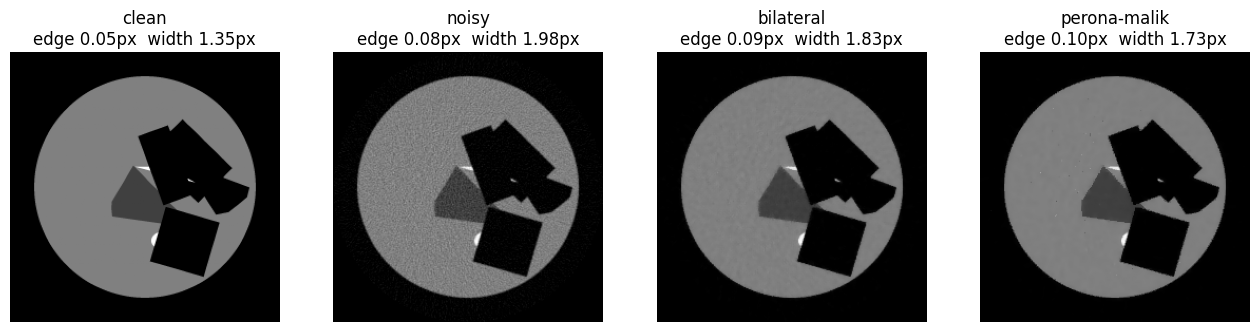

In [14]:
# [RUN NOW] try both filters once with default settings, to see what 'edge-preserving' looks like
import numpy as np, matplotlib.pyplot as plt
from phantom import make_phantom
from scanner import scan
from baselines import bilateral, perona_malik
from metrics import edge_metrics
img, e, _ = make_phantom(np.random.default_rng(7))
noisy = scan(img, 1e4, rng=np.random.default_rng(0))
b = bilateral(noisy.astype(np.float32), 7, 0.1, 2.0)
p = perona_malik(noisy.astype(np.float32), 20, 0.05, 0.15)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (t, x) in zip(ax, [("clean", img), ("noisy", noisy), ("bilateral", b), ("perona-malik", p)]):
    m = edge_metrics(x, img, e)
    a.imshow(x, cmap="gray", vmin=0, vmax=1); a.set_title(f"{t}\nedge {m['mean']:.2f}px  width {m['esf_median']:.2f}px"); a.axis("off")
plt.show()

## 6. Models  (`models.py`)
An autoencoder squeezes the image through a bottleneck, and the squeeze throws away fine detail (edges). **Skip connections** hand high-resolution features straight from encoder to decoder. **U-Net** = encoder + decoder + a skip at every level. Every model outputs *input + correction* (residual).

Three models, parameter counts matched (~1.9 M), so any difference comes from structure, not size:
- **Plain CNN:** no downsampling, no skips.
- **Hourglass:** U-Net shape with the skips removed.
- **U-Net:** the real thing.

In [15]:
# [RUN NOW] run the model tests: output shapes, parameter counts, skip wiring
%run models.py

All models.py tests passed.


<Figure size 640x480 with 0 Axes>

In [16]:
# [RUN NOW] print the parameter counts, to confirm the comparison is fair
from models import UNet, HourglassNoSkip, count_params, match_plaincnn
u = UNet(16, 4)
print({"UNet": count_params(u), "Hourglass": count_params(HourglassNoSkip(16, 4)), "PlainCNN (matched)": count_params(match_plaincnn(count_params(u)))})

{'UNet': 1939104, 'Hourglass': 1743264, 'PlainCNN (matched)': 1932336}


## 7. Losses  (`losses.py`)
A loss is what the network is punished for. Why the choice matters: under MSE the best possible answer is the **posterior mean**. If noise leaves the edge position uncertain, the mean over the possible positions is a ramp, i.e. a blur. L1 targets the median, which stays a sharp step.

10-90% width of MSE-optimal edge (px): 14


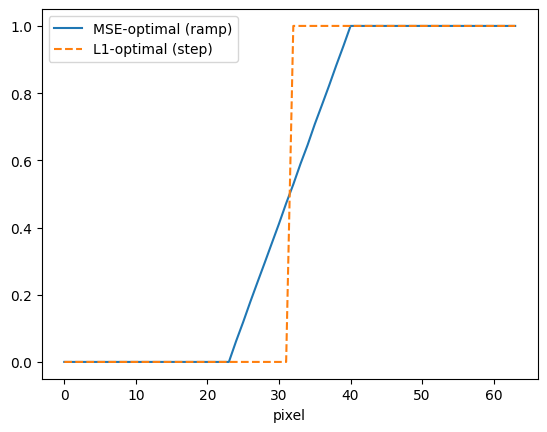

In [17]:
# [RUN NOW] 1-D proof that MSE blurs edges and L1 does not (no network involved)
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(0)
n, K = 64, 20000
x = np.arange(n)
pos = rng.integers(24, 41, K)                    # unknown edge position, uniform 24..40
steps = (x[None, :] >= pos[:, None]).astype(float)
mse_opt = steps.mean(0)                          # best output under MSE = posterior mean
l1_opt = np.median(steps, 0)                     # best output under L1 = posterior median
j = np.where((mse_opt > .1) & (mse_opt < .9))[0]
print('10-90% width of MSE-optimal edge (px):', len(j))
plt.plot(x, mse_opt, label='MSE-optimal (ramp)'); plt.plot(x, l1_opt, '--', label='L1-optimal (step)')
plt.legend(); plt.xlabel('pixel'); plt.show()

**Check yourself:** what sets the width of the ramp? (The uncertainty of the edge position. Chapter 10 tests this on real noisy phantoms.)

The four terms we use: **L1** (pixel error), **GDL** (match the gradients, so edges must stay sharp), **1-SSIM** (match local structure), **edge-weighted L1** (pixel error counted more near the true edge). Total = L1 + 0.5*GDL + 0.2*(1-SSIM).

In [18]:
# [RUN NOW] run the loss tests, including a check against skimage's SSIM (6 'ok' lines expected)
%run losses.py

ok test_l1_mse_known
ok test_gdl
ok test_ssim_matches_skimage
ok test_ssim_loss
ok test_edge_weighted
ok test_composite
All losses tests passed.


<Figure size 640x480 with 0 Axes>

In [19]:
# [RUN NOW] what each loss says about a blurred edge versus a noisy edge
import torch, torch.nn.functional as F
from losses import l1_loss, gdl_loss, ssim_loss
t = torch.zeros(1, 1, 64, 64); t[..., 32:] = 1.0
blur = F.avg_pool2d(F.pad(t, (3, 3, 3, 3), mode="replicate"), 7, 1)
noise = t + 0.05 * torch.randn_like(t)
for n, p in [("blurred edge", blur), ("noisy edge", noise)]:
    print(f"{n:13s} L1 {l1_loss(p, t).item():.4f} | GDL {gdl_loss(p, t).item():.4f} | 1-SSIM {ssim_loss(p, t).item():.4f}")

blurred edge  L1 0.0268 | GDL 0.0272 | 1-SSIM 0.1494
noisy edge    L1 0.0404 | GDL 0.1147 | 1-SSIM 0.6561


## 8. Data and training  (`data.py`, `train.py`)
200 train / 20 val / 30 test / 30 hole phantoms from disjoint seeds, so no test phantom is ever seen in training. Training noise: N0 = 2.5e3 ... 2e4 (noisy PSNR ~26-33 dB). Testing adds **N0 = 1e3 and 1e5, which the network never sees**. Training uses random 128x128 crops with flips and rotations (exact, so the edge truth stays valid). The final-epoch weights are used; no checkpoint picking.

Note: even a noise-free reconstruction of a phantom is only ~37 dB from the phantom, so N0 above ~5e4 all look alike.

In [20]:
# [RUN NOW] run the data tests: hole phantoms measure correctly, splits do not overlap, cache works
%run data.py

ok test_hole_phantom_and_diameter_metric
ok test_splits_disjoint_and_truth_matches_clean
ok test_build_split_small
All data tests passed.


In [21]:
# [RUN NOW] run the training tests (trains 4 tiny models for a few steps, 1-2 min on CPU; loss must go down)
%run train.py

ok test_dataset_geometry_consistent
ok test_train_each_model_and_denoise
All train tests passed.


In [22]:
# [RUN ONCE] build the datasets (5-12 min the first time, instant afterwards because they are cached in ./data)
import os, time, numpy as np, pandas as pd, data
from train import train, denoise, save_run, load_run
from experiments import *
from baselines import bilateral, perona_malik
t0 = time.time()
tr_d, va, te, ho = (data.build_split(n) for n in ("train", "val", "test", "holes"))
va_tr, te_tr, ho_tr = (data.truths(n) for n in ("val", "test", "holes"))
LV = data.TEST_N0
print(round(time.time() - t0), "s | train noisy array:", tr_d["noisy"].shape)

734 s | train noisy array: (200, 4, 256, 256)


## 9. Experiments  (`experiments.py`)
Every method is scored on the same 30 test phantoms at the same noise levels. The classical filters are tuned **twice**, once for best PSNR and once for best edge error, so nobody can say they were handicapped.

13 training runs: U-Net and Plain CNN with composite loss (3 seeds each, for error bars) + Hourglass, U-Net with MSE / L1 / edge-weighted loss, and a GDL-weight sweep (0.25, 1, 2).

**Kaggle, in 4 lines:** upload the `.py` files as a Dataset named `ct11-code`; new notebook with GPU T4 on; first cell `import sys; sys.path.insert(0, "/kaggle/input/ct11-code")`; run the cells from "build the datasets" to "evaluate". Download `runs/` and `results.csv` afterwards.

In [23]:
# [RUN NOW] run the evaluation-helper tests (4 'ok' lines expected)
%run experiments.py

ok test_evaluate_identity_and_blur
ok test_holes_shrink_detected
ok test_blur_law_recovers_exponents
ok test_tune_filter_and_rank
All experiments tests passed.


In [24]:
# [RUN ONCE] ~3 min | give each classical filter its best settings per noise level, using validation data only
B_GRID = dict(d=[7], sigma_color=[0.05, 0.1, 0.2, 0.4], sigma_space=[1.5, 3.0])
P_GRID = dict(n_iter=[10, 20, 40], kappa=[0.02, 0.05, 0.1], gamma=[0.15])
tuned = {}
for j, N0 in enumerate(LV):
    nz, cl, trv = va["noisy"][:8, j], va["clean"][:8], va_tr[:8]
    tuned[N0] = dict(bil=tune_filter(bilateral, B_GRID, nz, cl, trv)[:2], pm=tune_filter(perona_malik, P_GRID, nz, cl, trv)[:2])
    print(N0, tuned[N0])

1000.0 {'bil': ({'d': 7, 'sigma_color': 0.4, 'sigma_space': 3.0}, {'d': 7, 'sigma_color': 0.4, 'sigma_space': 3.0}), 'pm': ({'n_iter': 40, 'kappa': 0.1, 'gamma': 0.15}, {'n_iter': 10, 'kappa': 0.1, 'gamma': 0.15})}
2500.0 {'bil': ({'d': 7, 'sigma_color': 0.2, 'sigma_space': 3.0}, {'d': 7, 'sigma_color': 0.4, 'sigma_space': 3.0}), 'pm': ({'n_iter': 20, 'kappa': 0.1, 'gamma': 0.15}, {'n_iter': 10, 'kappa': 0.1, 'gamma': 0.15})}
5000.0 {'bil': ({'d': 7, 'sigma_color': 0.1, 'sigma_space': 3.0}, {'d': 7, 'sigma_color': 0.4, 'sigma_space': 1.5}), 'pm': ({'n_iter': 10, 'kappa': 0.1, 'gamma': 0.15}, {'n_iter': 10, 'kappa': 0.02, 'gamma': 0.15})}
10000.0 {'bil': ({'d': 7, 'sigma_color': 0.1, 'sigma_space': 3.0}, {'d': 7, 'sigma_color': 0.4, 'sigma_space': 1.5}), 'pm': ({'n_iter': 40, 'kappa': 0.05, 'gamma': 0.15}, {'n_iter': 10, 'kappa': 0.02, 'gamma': 0.15})}
20000.0 {'bil': ({'d': 7, 'sigma_color': 0.1, 'sigma_space': 3.0}, {'d': 7, 'sigma_color': 0.4, 'sigma_space': 1.5}), 'pm': ({'n_iter': 

In [25]:
# [RUN NOW] time ONE epoch so you know what the full training will cost on this machine
m_, h_ = train("unet", "composite", tr_d, None, epochs=1, log=lambda r: None)
print("seconds per epoch:", h_[0]["secs"], "-> all 13 runs x 20 epochs ~", round(13 * 20 * h_[0]["secs"] / 3600, 1), "hours")

seconds per epoch: 1.7 -> all 13 runs x 20 epochs ~ 0.1 hours


In [26]:
# [KAGGLE] train all 13 networks. Safe to stop and restart: runs already saved in ./runs are skipped.
RUNS = {  # name: (model, loss, loss settings, seeds)
    "unet-composite":      ("unet", "composite", {}, [0, 1, 2]),
    "plain-composite":     ("plain", "composite", {}, [0, 1, 2]),
    "hourglass-composite": ("hourglass", "composite", {}, [0]),
    "unet-mse":            ("unet", "mse", {}, [0]),
    "unet-l1":             ("unet", "l1", {}, [0]),
    "unet-edgew+gdl":      ("unet", "edgew+gdl", {}, [0]),
    "unet-gdl0.25":        ("unet", "composite", dict(w_gdl=0.25), [0]),
    "unet-gdl1":           ("unet", "composite", dict(w_gdl=1.0), [0]),
    "unet-gdl2":           ("unet", "composite", dict(w_gdl=2.0), [0]),
}
EPOCHS = 20
os.makedirs("runs", exist_ok=True)
for name, (m, l, kw, seeds) in RUNS.items():
    for s in seeds:
        p = f"runs/{name}-s{s}.pt"
        if os.path.exists(p): continue
        model, hist = train(m, l, tr_d, va, epochs=EPOCHS, seed=s, loss_kw=kw, log=lambda r: None)
        save_run(p, model, hist, dict(model=m, loss=l, kw=kw, seed=s, epochs=EPOCHS))
        print(name, s, hist[-1])

unet-composite 0 {'epoch': 20, 'train': 0.017285751635208724, 'secs': 1.6, 'val_l1': [0.008346876129508018, 0.005101979244500399, 0.0040446193888783455, 0.0034046091604977846, 0.0030084853060543537, 0.0025852143298834562]}
unet-composite 1 {'epoch': 20, 'train': 0.017032457571476697, 'secs': 1.5, 'val_l1': [0.008269619196653366, 0.005111425183713436, 0.003994013648480177, 0.003297195304185152, 0.0028719117399305105, 0.0024103987962007523]}
unet-composite 2 {'epoch': 20, 'train': 0.016663296669721602, 'secs': 1.4, 'val_l1': [0.008085174486041069, 0.004909195937216282, 0.0038596889935433865, 0.0032270222436636686, 0.0028385058976709843, 0.0024156877771019936]}
plain-composite 0 {'epoch': 20, 'train': 0.006611548033542931, 'secs': 12.8, 'val_l1': [0.004395922180265188, 0.0024433883372694254, 0.0017384199891239405, 0.001304743578657508, 0.0010265092132613063, 0.0007159503875300288]}
plain-composite 1 {'epoch': 20, 'train': 0.006928866910748184, 'secs': 12.8, 'val_l1': [0.004440553020685911

In [27]:
# [AFTER TRAINING] ~10 min | score every method (noisy input, 4 tuned filters, all networks) at all 6 noise levels
rows, nets = [], {}
def add(method, N0, df, seed=None):
    rows.append(dict(method=method, N0=N0, seed=seed, **df.mean().to_dict()))
for j, N0 in enumerate(LV):
    nz, cl = te["noisy"][:, j], te["clean"]
    add("noisy", N0, evaluate(nz, cl, te_tr))
    for key, fn, nm in [("bil", bilateral, "bilateral"), ("pm", perona_malik, "perona-malik")]:
        for k, tag in enumerate(["psnr-tuned", "edge-tuned"]):
            kw = tuned[N0][key][k]
            add(f"{nm} ({tag})", N0, evaluate(np.stack([fn(x.astype(np.float32), **kw) for x in nz]), cl, te_tr))
for name, (m, l, kw, seeds) in RUNS.items():
    for s in seeds:
        p = f"runs/{name}-s{s}.pt"
        if not os.path.exists(p): continue
        nets[(name, s)] = load_run(p)[0]
        for j, N0 in enumerate(LV):
            add(name, N0, evaluate(denoise(nets[(name, s)], te["noisy"][:, j]), te["clean"], te_tr), s)
res = pd.DataFrame(rows); res.to_csv("results.csv", index=False)
print(len(res), "rows saved to results.csv")

108 rows saved to results.csv


In [28]:
# [AFTER TRAINING] the headline table: average over the noise levels the networks trained on
cols = ["psnr", "ssim", "edge", "p95", "worst", "esf"]   # edge/p95/worst/esf in pixels, lower = better (psnr/ssim higher = better)
seen = [n for n in LV if n in data.TRAIN_N0]
print(res[res.N0.isin(seen)].groupby("method")[cols].mean().round(3))

                             psnr   ssim   edge    p95  worst    esf
method                                                              
bilateral (edge-tuned)     33.169  0.914  0.077  0.200  1.207  3.709
bilateral (psnr-tuned)     36.920  0.914  0.112  0.288  0.769  2.509
hourglass-composite        30.046  0.561  0.132  0.357  1.049  2.027
noisy                      30.046  0.561  0.132  0.357  1.049  2.027
perona-malik (edge-tuned)  32.788  0.726  0.130  0.347  0.966  2.134
perona-malik (psnr-tuned)  36.450  0.942  0.158  0.423  1.074  2.291
plain-composite            44.653  0.996  0.085  0.216  0.701  1.384
unet-composite             39.566  0.984  0.091  0.240  0.838  1.642
unet-edgew+gdl             41.823  0.983  0.087  0.227  0.836  1.488
unet-gdl0.25               39.587  0.983  0.087  0.229  0.794  1.637
unet-gdl1                  40.039  0.984  0.091  0.238  0.822  1.616
unet-gdl2                  39.945  0.985  0.092  0.243  0.842  1.621
unet-l1                    41.098 

In [29]:
# [AFTER TRAINING] robustness: edge error per noise level. N0=1e3 and 1e5 were never seen in training.
print(res.pivot_table(index="method", columns="N0", values="edge").round(3))

N0                         1000.0    2500.0    5000.0    10000.0   20000.0   \
method                                                                        
bilateral (edge-tuned)        0.187     0.112     0.084     0.063     0.050   
bilateral (psnr-tuned)        0.187     0.140     0.131     0.099     0.080   
hourglass-composite           0.340     0.205     0.144     0.103     0.076   
noisy                         0.340     0.205     0.144     0.103     0.076   
perona-malik (edge-tuned)     0.314     0.191     0.145     0.104     0.078   
perona-malik (psnr-tuned)     0.303     0.196     0.145     0.171     0.121   
plain-composite               0.189     0.115     0.089     0.072     0.064   
unet-composite                0.215     0.129     0.096     0.075     0.063   
unet-edgew+gdl                0.195     0.121     0.092     0.073     0.062   
unet-gdl0.25                  0.198     0.121     0.092     0.073     0.061   
unet-gdl1                     0.214     0.128     0.

## 10. What is new here
- **A. Does PSNR pick the right model?** If the PSNR ranking disagrees with the edge/size ranking, the usual score picks the wrong model for measurement work.
- **B. Edge-blur law:** MSE-trained networks blur because the edge position is uncertain. Prediction: blur width grows with noise (exponent alpha ~ +1) and shrinks with contrast (beta ~ -1). Fit it; report whatever comes out.
- **C. Small-feature bias:** how much does each method shrink or inflate a round hole, as a function of its size?

In [30]:
# [AFTER TRAINING] finding A: rank methods by PSNR and by edge error at N0=5e3; rho near -1 = PSNR agrees with edge accuracy
sub = res[res.N0 == 5e3].groupby("method")[["psnr", "edge", "esf"]].mean()
print(sub.sort_values("psnr", ascending=False).round(3)); print(rank_report(sub))

                             psnr   edge    esf
method                                         
plain-composite            44.102  0.089  1.385
unet-edgew+gdl             41.480  0.092  1.487
unet-mse                   40.976  0.093  1.462
unet-l1                    40.841  0.095  1.531
unet-gdl1                  39.895  0.095  1.618
unet-gdl2                  39.810  0.097  1.619
unet-gdl0.25               39.473  0.092  1.635
unet-composite             39.438  0.096  1.641
bilateral (psnr-tuned)     36.030  0.131  2.273
perona-malik (psnr-tuned)  36.017  0.145  2.685
bilateral (edge-tuned)     33.256  0.084  3.587
perona-malik (edge-tuned)  29.334  0.145  2.035
hourglass-composite        28.854  0.144  2.043
noisy                      28.854  0.144  2.043
                  edge       esf
rho(psnr, .) -0.638767 -0.876652


In [31]:
# [AFTER TRAINING] finding C: hole-size error in px (negative = hole measured too small), by hole radius
H = []
for j, N0 in enumerate(data.HOLE_N0):
    nz = ho["noisy"][:, j]
    cand = {"noisy": nz, **{n: denoise(m, nz) for (n, s), m in nets.items() if s == 0}}
    for k, v in cand.items():
        h = evaluate_holes(v, ho["clean"], ho_tr); h["method"], h["N0"] = k, N0; H.append(h)
H = pd.concat(H); H["rbin"] = pd.cut(H.radius, [5, 8, 12, 17, 24])
print(H.pivot_table(index="method", columns=["N0", "rbin"], values="err", aggfunc="mean", observed=True).round(2))

N0                  5000.0                            20000.0          \
rbin                 (5, 8] (8, 12] (12, 17] (17, 24]  (5, 8] (8, 12]   
method                                                                  
hourglass-composite   -0.09   -0.05    -0.04    -0.04   -0.10   -0.06   
noisy                 -0.09   -0.05    -0.04    -0.04   -0.10   -0.06   
plain-composite       -0.18   -0.11    -0.08    -0.06   -0.18   -0.12   
unet-composite        -0.08   -0.04    -0.02    -0.01   -0.12   -0.08   
unet-edgew+gdl        -0.10   -0.06    -0.04    -0.03   -0.11   -0.07   
unet-gdl0.25          -0.12   -0.07    -0.04    -0.03   -0.15   -0.10   
unet-gdl1             -0.08   -0.03    -0.01    -0.01   -0.12   -0.08   
unet-gdl2             -0.12   -0.06    -0.03    -0.02   -0.16   -0.09   
unet-l1               -0.11   -0.07    -0.05    -0.04   -0.12   -0.08   
unet-mse              -0.08   -0.04    -0.03    -0.03   -0.10   -0.06   

N0                                     
rbin      

In [32]:
# [AFTER TRAINING] finding B: fit blur width ~ noise^alpha * contrast^beta for the MSE and composite U-Nets
sig = {N0: float(np.std(te["noisy"][:, j] - te["clean"])) for j, N0 in enumerate(LV)}
for name in ["unet-mse", "unet-composite"]:
    W, C, S = [], [], []
    for j, N0 in enumerate(LV):
        w, c, s_ = collect_blur(denoise(nets[(name, 0)], te["noisy"][:, j]), te["clean"], te_tr, sig[N0])
        W.append(w); C.append(c); S.append(s_)
    print(name, blur_law(np.concatenate(W), np.concatenate(C), np.concatenate(S)))

unet-mse {'alpha': 0.35133584471758955, 'beta': -0.2718295429320787, 'r2': 0.16257149793995673, 'n': 305303}
unet-composite {'alpha': 0.17671602332139955, 'beta': -0.15159291433701214, 'r2': 0.07655781429475184, 'n': 410786}


## 11. Real CT  (`loader.py`, LIDC-IDRI)
Generalisation check only. Real slices have no exact edge truth, so no edge-error claims. The loader reads DICOM, converts to Hounsfield units, windows, normalises and resizes to 256x256.

In [42]:
import glob, shutil
for f in glob.glob("/kaggle/input/**/*.py", recursive=True): shutil.copy(f, "/kaggle/working/")
print(sorted(f.split("/")[-1] for f in glob.glob("/kaggle/working/*.py")))

['baselines.py', 'data.py', 'experiments.py', 'loader.py', 'losses.py', 'metrics.py', 'models.py', 'phantom.py', 'scanner.py', 'test_phantom.py', 'train.py']


In [43]:
# [RUN NOW] loader tests (pydicom warnings are harmless; expect "All 10 ... passed")
%run loader.py

/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'SERIES_P1'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> for allowed values for each VR.
  warn_and_log(msg)
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'SERIES_P2'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> for allowed values for each VR.
  warn_and_log(msg)
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'UID_SMALL_3'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> for allowed values for each VR.
  warn_and_log(msg)
/usr/local/lib/python3.13/dist-packages/pydicom/valuerep.py:440: UserWarning: Invalid value for VR UI: 'UID_LARGE_5'. Please see <https://dicom.nema.org/medical/dicom/current/output/html/part05.html#table_6.2-1> 

All 10 unit, shape, and adversarial tests in loader.py passed.


In [44]:
# [RUN ONCE] DICOM -> 256x256 .npy slices, at most 40 per patient
# [RUN ONCE] DICOM -> 256x256 .npy slices, at most 40 per patient
from loader import process_folder
DICOM_DIR = "/kaggle/input/datasets/radioacktiwe/lidc-project11-dataset"
out = process_folder(DICOM_DIR, "data/lidc", max_slices=40)
print(len(out), "patients,", sum(len(v) for v in out.values()), "slices")

25 patients, 775 slices


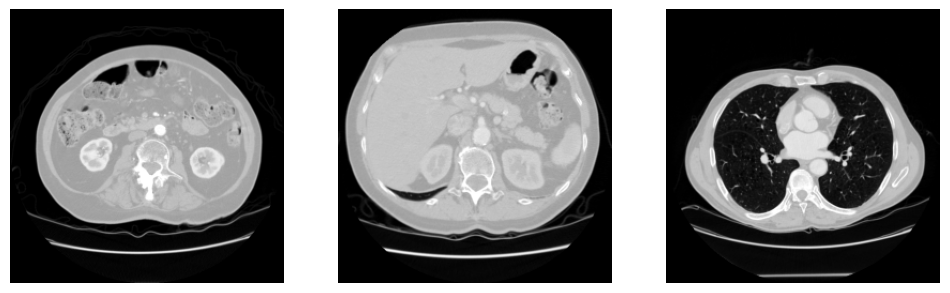

In [45]:
# [RUN NOW] look at 3 slices: dark lungs, grey tissue, bright spine (not blank, not inverted)
import glob, numpy as np, matplotlib.pyplot as plt
fs = sorted(glob.glob("data/lidc/*/*.npy"))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, f in zip(ax, fs[::max(1, len(fs) // 3)][:3]):
    a.imshow(np.load(f), cmap="gray", vmin=0, vmax=1); a.axis("off")
plt.show()

PSNR noisy: 27.2 | U-Net: 30.1


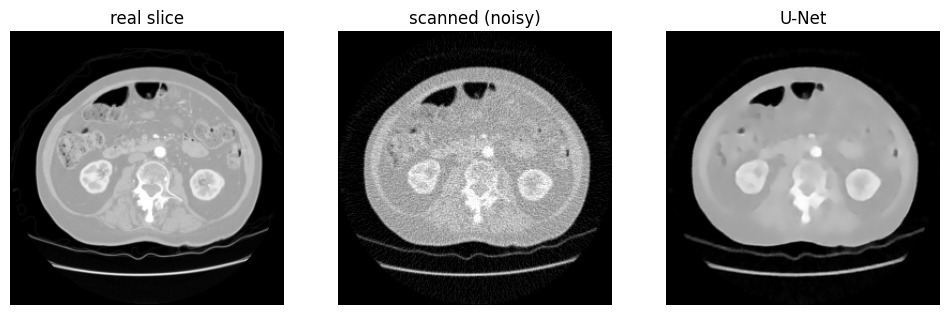

In [46]:
# [AFTER TRAINING] real slices -> simulated scan -> U-Net. Generalisation check only (no edge claims).
import glob, numpy as np, matplotlib.pyplot as plt
from scanner import scan
from metrics import psnr
fs = sorted(glob.glob("data/lidc/*/*.npy")); fs = fs[::max(1, len(fs) // 8)][:8]
yy, xx = np.mgrid[:256, :256]; disk = (np.hypot(yy - 127.5, xx - 127.5) < 127).astype(np.float32)   # scanner needs content inside a circle
real = np.stack([np.load(f) * disk for f in fs])
nz = np.stack([scan(r, 1e4, rng=np.random.default_rng(i)) for i, r in enumerate(real)])
den = denoise(nets[("unet-composite", 0)], nz)
print("PSNR noisy:", round(np.mean([psnr(np.clip(a, 0, 1), b) for a, b in zip(nz, real)]), 1),
      "| U-Net:", round(np.mean([psnr(np.clip(a, 0, 1), b) for a, b in zip(den, real)]), 1))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (t, x) in zip(ax, [("real slice", real[0]), ("scanned (noisy)", nz[0]), ("U-Net", den[0])]):
    a.imshow(np.clip(x, 0, 1), cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.savefig("fig_real.png", dpi=130); plt.show()

## 12. Limits and honest discussion
- **Phantoms are simple:** polygons and ellipses with flat materials. Real parts have texture, beam hardening and artefacts the simulation does not include.
- **Reconstruction floor:** a noise-free reconstruction of a phantom is already ~37 dB from the phantom, so PSNR above ~35 dB says little.
- **Edge metrics:** the worst-case error is one-directional (truth -> image), so invented edges are not counted. Corners and junctions are skipped (`n_used` vs `n_total`).
- **Real CT has no exact edge truth,** so chapter 11 supports a generalisation claim only.
- **Small experiment:** 1 seed for most ablations, 3 seeds only for U-Net vs Plain CNN, 20 epochs.
- **Classical filters** were tuned per noise level on validation data; the networks were not told the noise level.

**Result summary (fill in after the runs):** which method has the lowest edge error? Does the best-PSNR method also win on edge error and hole size? What did the blur-law fit give?